# Holding out; MAE and MAPE in the business's units: how is a forecast scored honestly, in cups and in rupees?

**Week 4, Friday, concept notebook 3 of 4, beside chapter 3 of the deck.** The chai stall is invented: it sits at a hostel gate, and every cup in this notebook is an invented number written by the day's seeded generator. Notebook
02 built three copy rules; this notebook scores a rule on days it never saw.

**Who needs the answer.** The stall's owner (invented), who wants to know how wrong the milk
order could be before trusting a rule, and Flipkart's regional operations head, who must
say yes or no to a vendor's curve before a shift is booked.

**The questions on the way.** Which days do we hide? How is a miss counted? When does a
percent mislead? Which way is the rule wrong, and what does that cost?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

# fourteen days of the invented stall, Saturday 1 to Friday 14 February 2025; the last three are hidden
days = pd.read_csv("../data/C2_W04_D05_chai_stall_hidden_days_STUDENT.csv")
unsold_rs, short_rs = 6, 12      # a cup unsold wastes Rs 6 of milk; a cup short loses Rs 12 of margin (invented)
check("fourteen days, the last three hidden", len(days) == 14 and days.hidden.tolist() == [0] * 11 + [1] * 3)
days                             # every number invented

PASS fourteen days, the last three hidden


,day,date,weekday,cups,hidden
0,1,2025-02-01,Sat,103,0
1,2,2025-02-02,Sun,63,0
2,3,2025-02-03,Mon,102,0
3,4,2025-02-04,Tue,102,0
4,5,2025-02-05,Wed,104,0
5,6,2025-02-06,Thu,102,0
6,7,2025-02-07,Fri,104,0
7,8,2025-02-08,Sat,103,0
8,9,2025-02-09,Sun,62,0
9,10,2025-02-10,Mon,103,0


## Which days do we hide?

The owner orders milk for the next three days. To judge a rule, hide some days, forecast
them as if each were tomorrow, and count the misses.

**Predict before you run.** To judge a three-day milk order, which three of the fourteen
days do you hide?

a) The last three: days 12, 13 and 14
b) Three days at random, so any weekday may be tested
c) The three busiest, since they cost the most
d) Any three; it makes no difference which

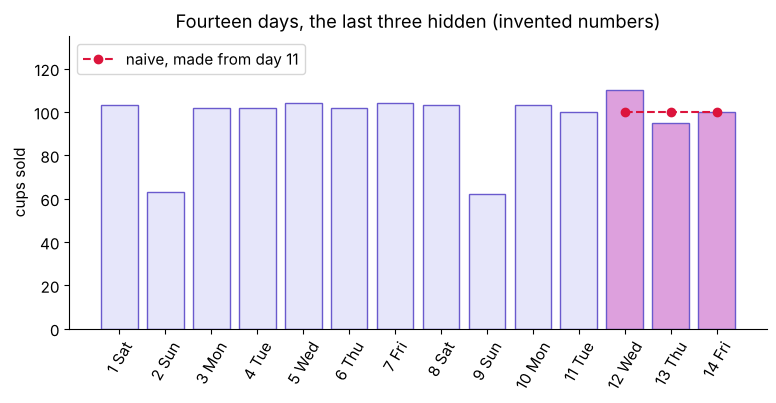

training days: 11; hidden days: 3, which sold [110, 95, 100]; naive says 100 for each
PASS the hidden days are the latest
PASS as many hidden days as the order reaches ahead


In [2]:
train, hidden = days[days.hidden == 0], days[days.hidden == 1]
origin = int(train.cups.iloc[-1])                         # day 11, the last day a rule may see
forecast = [origin] * len(hidden)                         # naive: day 11 repeated for each hidden day
fig, ax = plt.subplots()
ax.bar(days.day, days.cups, color=["lavender"] * len(train) + ["plum"] * len(hidden), edgecolor="slateblue")
ax.plot(hidden.day, forecast, color="crimson", ls="--", marker="o", label="naive, made from day 11")
ax.set_xticks(days.day, days.day.astype(str) + " " + days.weekday, rotation=60)
ax.set_ylim(0, 135)
ax.set_ylabel("cups sold")
ax.set_title("Fourteen days, the last three hidden (invented numbers)")
ax.legend(loc="upper left")
plt.show()
print(f"training days: {len(train)}; hidden days: {len(hidden)}, which sold {hidden.cups.tolist()}; "
      f"naive says {origin} for each")
check("the hidden days are the latest", hidden.day.min() > train.day.max())
check("as many hidden days as the order reaches ahead", len(hidden) == 3)

**What happened.** The answer is a. Hide the latest days, at least as many as the forecast
must reach ahead: three here. Day 11 is the **origin**, the last day a rule may see; three
days ahead is the **horizon**; days 1 to 11 are the **training** days and days 12 to 14 the
**hidden** days, also called the hold-out or the test set. Tomorrow looks most like the
newest days, and a random hole would let a rule borrow days that come after the one it
forecasts, which a real tomorrow never offers. The test set should be "at least as large
as the maximum forecast horizon required" (Forecasting: Principles and Practice, section
5.8, checked 13 October 2026).

## How is a miss counted?

By hand first. Naive says 100 for each hidden day, and days 12 to 14 sold 110, 95 and 100.
A **miss** here is the forecast minus what sold, so a positive miss is cups unsold and a
negative one cups short: -10, +5 and 0.

- **MAE**, the mean absolute error, drops the signs and averages: (10 + 5 + 0) / 3 = 5.0
  cups.
- **MAPE**, the mean absolute percentage error, divides each miss by what sold before
  averaging: (10/110 + 5/95 + 0/100) / 3, about 4.8 percent.
- **The lean** keeps the signs: (-10 + 5 + 0) / 3, about -1.7 cups, so the rule runs low.
- **In rupees:** 10 cups short at Rs 12 and 5 unsold at Rs 6, Rs 120 + Rs 30 = Rs 150.

Forecasting: Principles and Practice writes the error the other way round, sold minus
forecast, so its signs flip and its sizes stay the same.

In [3]:
def mae(misses):
    return sum(abs(m) for m in misses) / len(misses)                      # sizes, signs dropped, averaged

def mape(misses, sold):
    return sum(abs(m) / s for m, s in zip(misses, sold)) / len(misses)    # each miss over what sold

def lean(misses):
    return sum(misses) / len(misses)                                      # signs kept: below zero runs low

def rupees(misses):
    return sum(m * unsold_rs if m > 0 else -m * short_rs for m in misses)  # unsold at Rs 6, short at Rs 12

sold = [int(s) for s in hidden.cups]
misses = [f - s for f, s in zip(forecast, sold)]
print(f"misses {misses}: MAE {mae(misses):.1f} cups, MAPE {mape(misses, sold):.1%}, "
      f"lean {lean(misses):+.1f} cups, cost Rs {rupees(misses)}")
check("by hand and by code, MAE is 5.0 cups", mae(misses) == (10 + 5 + 0) / 3)
check("by hand and by code, MAPE is about 4.8 percent", round(mape(misses, sold), 4) == round((10 / 110 + 5 / 95 + 0 / 100) / 3, 4))
check("the rule runs low, and its misses cost Rs 150", lean(misses) < 0 and rupees(misses) == 10 * 12 + 5 * 6)

misses [-10, 5, 0]: MAE 5.0 cups, MAPE 4.8%, lean -1.7 cups, cost Rs 150
PASS by hand and by code, MAE is 5.0 cups
PASS by hand and by code, MAPE is about 4.8 percent
PASS the rule runs low, and its misses cost Rs 150


**What happened.** Both scores, named last: MAE is the mean of the misses' sizes, in the
unit the cost is counted in, cups here; MAPE is the mean of each miss's size over what
sold, in percent, which lets you compare stalls of different sizes. A percent cannot be
priced, which is why the owner's score is the MAE, priced in rupees.

## When does a percent mislead?

**Predict before you run.** Two invented days, apart from the stall's record: an ordinary
day forecast at 100 that sold 85, and a rain day, the stall shut after an hour, forecast at
20 that sold 5. Each misses by 15 cups. What percent miss does the rain day score?

example                                      day  forecast  sold
   mape                          an ordinary day       100    85
   mape a rain day, the stall shut after an hour        20     5


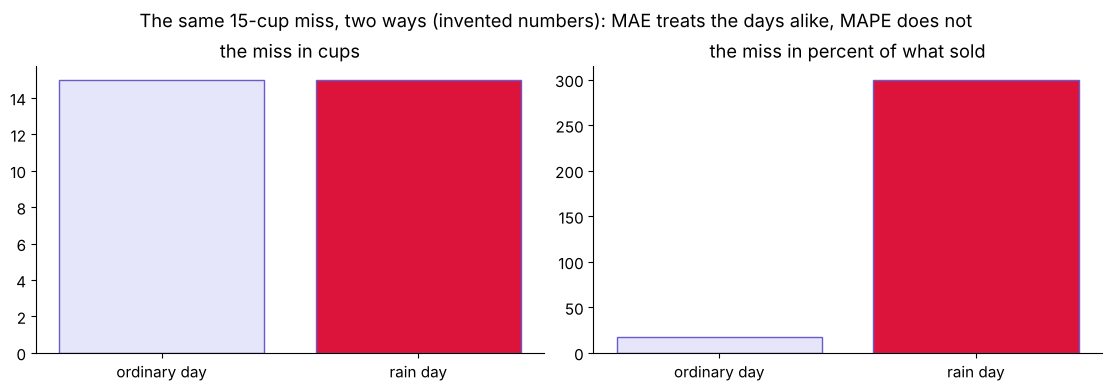

MAE 15 cups; percent misses 17.6% and 300%; MAPE 158.8%
PASS both days miss by the same 15 cups
PASS the rain day's percent swamps the ordinary day's


In [4]:
what_if = pd.read_csv("../data/C2_W04_D05_chai_stall_what_ifs_STUDENT.csv")   # invented what-ifs
pair = what_if[what_if.example == "mape"]
print(pair.to_string(index=False))
miss = (pair.forecast - pair.sold).tolist()
pct = [abs(m) / s for m, s in zip(miss, pair.sold)]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), constrained_layout=True)
for ax, values, title in [(axes[0], [abs(m) for m in miss], "the miss in cups"),
                          (axes[1], [p * 100 for p in pct], "the miss in percent of what sold")]:
    ax.bar(["ordinary day", "rain day"], values, color=["lavender", "crimson"], edgecolor="slateblue")
    ax.set_title(title)
fig.suptitle("The same 15-cup miss, two ways (invented numbers): MAE treats the days alike, MAPE does not")
plt.show()
print(f"MAE {mae(miss):.0f} cups; percent misses {pct[0]:.1%} and {pct[1]:.0%}; MAPE {mape(miss, pair.sold.tolist()):.1%}")
check("both days miss by the same 15 cups", abs(miss[0]) == abs(miss[1]) == 15)
check("the rain day's percent swamps the ordinary day's", pct[1] > 10 * pct[0])

**What happened.** The rain day scores 300 percent and the ordinary day 17.6 percent, so
their MAPE is 158.8 percent while their MAE stays 15 cups. MAPE divides by what sold, so a
day that sells close to zero swamps it: percentage errors are "infinite or undefined if
y_t = 0" and take "extreme values if any y_t is close to zero" (Forecasting: Principles and
Practice, section 5.8, checked 13 October 2026). Keep MAE for the order and MAPE for
comparing stalls of different sizes, on periods that never sell close to zero.

## Which way is the rule wrong, and what does that cost?

**Predict before you run.** Two rules each miss two days by 10 cups. Rule P runs over on
both days (+10, +10); rule Q runs over, then short (+10, -10). Both score an MAE of 10.
Which costs more, at Rs 6 a cup unsold and Rs 12 a cup short?

           misses   MAE  lean  cost Rs
rule                                  
rule P   [10, 10]  10.0  10.0      120
rule Q  [10, -10]  10.0   0.0      180


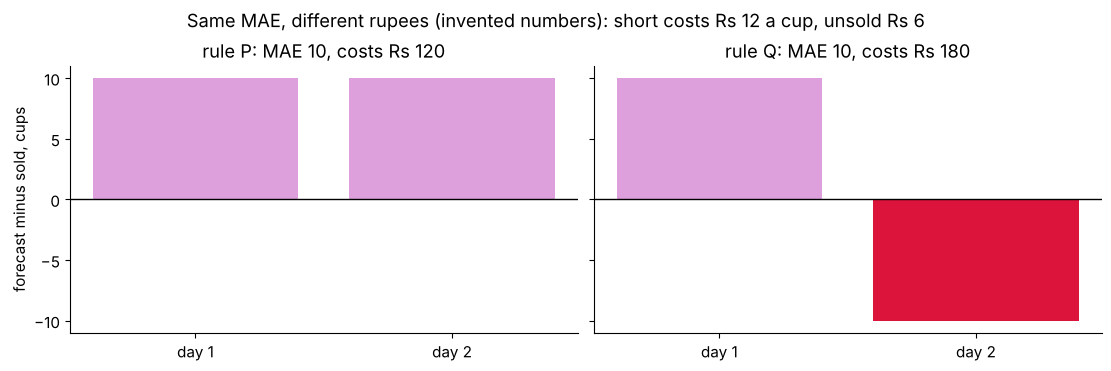

PASS both rules share an MAE of 10
PASS rule P costs Rs 120 and rule Q Rs 180


In [5]:
rows = []
for name in ["rule P", "rule Q"]:
    r = what_if[what_if.example == name]
    m = (r.forecast - r.sold).tolist()
    rows.append({"rule": name, "misses": m, "MAE": mae(m), "lean": lean(m), "cost Rs": rupees(m)})
table = pd.DataFrame(rows).set_index("rule")
print(table.to_string())
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True, constrained_layout=True)
for ax, (name, row) in zip(axes, table.iterrows()):
    ax.bar(["day 1", "day 2"], row.misses, color=["crimson" if m < 0 else "plum" for m in row.misses])
    ax.axhline(0, color="black", lw=1)
    ax.set_title(f"{name}: MAE {row.MAE:.0f}, costs Rs {row['cost Rs']}")
axes[0].set_ylabel("forecast minus sold, cups")
fig.suptitle("Same MAE, different rupees (invented numbers): short costs Rs 12 a cup, unsold Rs 6")
plt.show()
check("both rules share an MAE of 10", table.MAE.tolist() == [10, 10])
check("rule P costs Rs 120 and rule Q Rs 180", table["cost Rs"].tolist() == [120, 180])

**What happened.** Rule Q costs more. Rule P, always over, wastes 20 cups of milk at Rs 6:
Rs 120. Rule Q runs short on day 2, and a cup short costs Rs 12: Rs 60 + Rs 120 = Rs 180.

**The plausible wrong answer.** "Both rules score MAE 10, so they are equally good." **The
decision it misleads:** milk ordered at the forecast when the misses run short. **The
check:** the sign of each miss, the lean. **The fix:** report the MAE and the lean together,
and price each direction.

**Your turn.** Score the seasonal naive on the same three hidden days. With a beat of 7 days
it copies days 5, 6 and 7, the same weekdays a week before days 12, 13 and 14. Fill the
blanks, type the lines into the empty cell below and run them; the checks print PASS when
the scores are right.

```python
week_back = days.cups.iloc[4:7].tolist()          # days 5 to 7 (invented)
misses = [f - s for f, s in zip(___, sold)]
print(misses, mae(misses), lean(misses), rupees(misses))
check("the seasonal naive's MAE is about 5.7 cups", round(mae(___), 1) == 5.7)
check("its misses cost Rs 138", rupees(___) == 138)
```

Then compare it with naive's 5.0 cups: which rule scores better on these three days, and
why can the weekly beat add nothing when no Sunday sits among the hidden days?

## Which rules does the chapter leave?

1. Hide the latest periods, at least as many as the forecast must reach ahead, and forecast
   them all from one origin.
2. Fix the measure before anyone scores, in the unit the cost is in.
3. Keep MAPE for comparing series of different sizes, and never on periods that sell close
   to zero.
4. Report which way a rule leans beside how far it misses, because a miss short and a miss
   over cost different amounts.

**In the interview.** [S] "How do you evaluate a forecast?" A hire-grade answer holds four
moves: hold out the latest periods, as many as the horizon; fix the error measure in the
business's unit before scoring; compare with the naive and the seasonal naive; price each
direction of the miss.

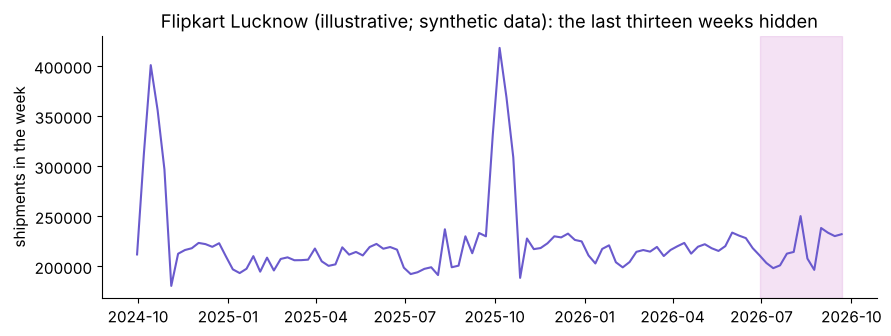

hidden: 2026-06-29 to 2026-09-21; origin: 2026-06-22
a spare shipment costs Rs 5.42 and a late one Rs 25
PASS thirteen hidden weeks, the latest
PASS the hidden weeks cover the plan's ten-week horizon


In [6]:
weekly = pd.read_csv("../data/C2_W04_D05_weekly_shipments_STUDENT.csv", parse_dates=["week_start"])
costs = pd.read_csv("../data/C2_W04_D05_costs_STUDENT.csv").set_index("item").rs
y = weekly.set_index("week_start").shipments                    # Flipkart Lucknow, the case's 104 weeks
train, held = y.iloc[:91], y.iloc[91:]                          # the training weeks, and the hidden ones
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(y.index, y.values, color="slateblue")
ax.axvspan(held.index[0], held.index[-1], color="plum", alpha=0.3)
ax.set_ylabel("shipments in the week")
ax.set_title("Flipkart Lucknow (illustrative; synthetic data): the last thirteen weeks hidden")
plt.show()
print(f"hidden: {held.index[0].date()} to {held.index[-1].date()}; origin: {train.index[-1].date()}")
print(f"a spare shipment costs Rs {costs['idle_packer_shift'] / 120:.2f} and a late one Rs {costs['late_shipment']}")
check("thirteen hidden weeks, the latest", len(held) == 13 and held.index[-1] == y.index[-1])
check("the hidden weeks cover the plan's ten-week horizon", len(held) >= 10)

## What did the chapter answer?

| Question | The stall's answer, in invented numbers |
|---|---|
| Which days do we hide? | The latest three, as many as the order reaches ahead, all forecast from day 11 |
| How is a miss counted? | MAE 5.0 cups; MAPE about 4.8 percent |
| When does a percent mislead? | On a day that sells close to zero: 300 percent for a 15-cup miss |
| Which way is the rule wrong, and what does that cost? | Low, by 1.7 cups a day; Rs 150 over the three days, and the same MAE can cost Rs 120 or Rs 180 |

At Flipkart the latest thirteen weeks, 29 June to 21 September 2026, are hidden, the origin
is the week of 22 June and the horizon ten weeks; a spare shipment costs Rs 5.42 and a late
one Rs 25. Chapter 6's notebook, `C2_W04_D05_06_case_holdout_scoreboard_STUDENT.ipynb`,
scores every rule and the vendor's curve there; notebook 04 asks when a forecast earns
trust.